# Network Autostep vs SGD and Adam | Simple Multi-GEOFF

Can a fully connected network keep separate subproblems apart? Each learner trains at a range of step-sizes, and two
measures show how sensitive it is to that step-size.

**Problem.** Simple multi-GEOFF: `N_TASKS` independent tasks, side by side. Each task has 21 inputs, 10 teacher LTUs
and 10 outputs, with $y = V \,\mathrm{ltu}(U x) + \epsilon$. The inputs $x$ and every weight in $U$ and $V$ are random
$\pm 1$ signs, the LTU thresholds are 0, and $\epsilon \sim N(0, 1)$. The problem changes over time: every
`PERMUTE_PERIOD` = 2000 / `N_TASKS` steps, one task chosen at random gets a random permutation of its outputs, as a
label permutation does. Each task thus changes about every 2000 steps.

**Network.** Fully connected: every input → 40 LTUs → every output, with a bias in each layer. Output weights and
biases start at 0. The loss is $\frac{1}{2}\|\hat{y} - y\|^2$, with one sample per update.

**Learners.**
- *Network Autostep* (proposed): Autostep on every weight, with each layer as its own linear learner. Each hidden LTU
  is standardized with running statistics and batch norm's backward pass. Hidden weights start in
  $U(-\alpha_0, \alpha_0)$, where $\alpha_0$ is Autostep's initial step-size.
- *SGD* and *Adam* (baselines): raw LTU outputs, and hidden weights that start LeCun uniform.

**Measures**, recorded at step 1 and over each window of 5000 steps. Seed $s$ gives every run the same teacher,
samples and permutations.
- *RMSE*. Its minimum is the noise std, 1.
- *Path purity*, averaged over the window: the share of all input → hidden → output path weight that starts and ends in the same
  task. The weight of a path is the product of $|w|$ along it. Purity is 1 when no path crosses tasks, and
  1/`N_TASKS` for even mixing.

**Plots.** The sensitivity plots show each measure averaged over the last 10% of steps, against the step-size. The
learning curves show every learner at every step-size. Each point and each curve is the mean over 5 seeds.

In [10]:
import equinox as eqx
import jax
import jax.numpy as jnp
import matplotlib.pyplot as plt
import numpy as np
import optax

In [11]:
# Problem: simple multi-GEOFF
N_TASKS = 4
N_INPUTS_PER_TASK = 21          # odd, so the input sum of a teacher LTU is never 0
N_TEACHER_LTUS_PER_TASK = 10
N_OUTPUTS_PER_TASK = 10
NOISE_STD = 1.0                 # noise on the targets, so the lowest possible RMSE
PERMUTE_PERIOD = 2000 // N_TASKS    # steps between output permutations, each of one task chosen at random

# Learners\
HIDDEN_SIZES = (N_TASKS * N_TEACHER_LTUS_PER_TASK,)    # LTUs in each hidden layer
META_STEP_SIZE = 0.02           # Autostep's mu
TAU = 1e4                       # Autostep's tau
STAT_RATE = 1e-3                # rate of the running statistics for standardization
VAR_FLOOR = 0.01                # smallest variance that standardization divides by

# Sweep
STEP_SIZES = 2.0 ** np.arange(-18, -3, 2)   # SGD's and Adam's step-size, and network Autostep's initial step-size
N_SEEDS = 5
N_STEPS = 500_000
WINDOW = 5_000                  # steps per recorded point
FINAL_FRACTION = 0.1            # the sensitivity plots use the last 10% of steps

## Problem

In [12]:
N_INPUTS = N_TASKS * N_INPUTS_PER_TASK
N_OUTPUTS = N_TASKS * N_OUTPUTS_PER_TASK


class Target(eqx.Module):
    # Each task is its own random network of LTUs: y = output_weights @ ltu(input_weights @ x) + noise.
    input_weights: jax.Array    # (task, teacher LTU, input)
    output_weights: jax.Array   # (task, output, teacher LTU)
    step: jax.Array

    def __init__(self, key):
        input_key, output_key = jax.random.split(key)
        input_shape = (N_TASKS, N_TEACHER_LTUS_PER_TASK, N_INPUTS_PER_TASK)
        output_shape = (N_TASKS, N_OUTPUTS_PER_TASK, N_TEACHER_LTUS_PER_TASK)
        self.input_weights = jax.random.rademacher(input_key, input_shape, jnp.float32)
        self.output_weights = jax.random.rademacher(output_key, output_shape, jnp.float32)
        self.step = jnp.array(0)

    def sample(self, key):
        """Returns the target for the next step and one sample (x, y). Every PERMUTE_PERIOD steps, one task chosen
        at random first gets a random permutation of its outputs."""
        task_key, permutation_key, x_key, noise_key = jax.random.split(key, 4)
        step = self.step + 1
        task = jax.random.randint(task_key, (), 0, N_TASKS)
        changes = (step % PERMUTE_PERIOD == 0) & (jnp.arange(N_TASKS) == task)
        permuted = self.output_weights[:, jax.random.permutation(permutation_key, N_OUTPUTS_PER_TASK)]
        output_weights = jnp.where(changes[:, None, None], permuted, self.output_weights)
        target = eqx.tree_at(lambda target: (target.output_weights, target.step), self, (output_weights, step))

        x = jax.random.rademacher(x_key, (N_TASKS, N_INPUTS_PER_TASK), jnp.float32)
        hidden = (jnp.einsum('thi,ti->th', target.input_weights, x) > 0).astype(jnp.float32)
        y = jnp.einsum('toh,th->to', target.output_weights, hidden)
        noise = NOISE_STD * jax.random.normal(noise_key, (N_OUTPUTS,))
        return target, x.reshape(-1), y.reshape(-1) + noise

## Layers

In [13]:
@jax.custom_vjp
def ltu(z):
    """1 where z > 0, else 0. The backward pass uses the sigmoid's derivative."""
    return (z > 0).astype(jnp.float32)


def ltu_fwd(z):
    return ltu(z), z


def ltu_bwd(z, out_grad):
    sigmoid = jax.nn.sigmoid(z)
    return (out_grad * sigmoid * (1 - sigmoid),)


ltu.defvjp(ltu_fwd, ltu_bwd)


def moving_average(mean, value):
    return mean + STAT_RATE * (value - mean)


@jax.custom_vjp
def standardize(x, mean, shift_grad_mean, scale_grad_mean):
    """(x - mean) / std, where std = sqrt(mean (1 - mean)) is the std of a bit."""
    return standardize_fwd(x, mean, shift_grad_mean, scale_grad_mean)[0]


def standardize_fwd(x, mean, shift_grad_mean, scale_grad_mean):
    variance = mean * (1 - mean)
    std = jnp.sqrt(jnp.maximum(variance, VAR_FLOOR))
    out = (x - mean) / std
    return out, (out, std, variance > VAR_FLOOR, shift_grad_mean, scale_grad_mean)


def standardize_bwd(saved, out_grad):
    # Batch norm's backward pass: dL/dx = (dL/dout - mean(dL/dshift) - out * mean(dL/dscale)) / std.
    # While the variance is at its floor, std does not depend on x, so the scale term drops out.
    # The running statistics get no gradient.
    out, std, unfloored, shift_grad_mean, scale_grad_mean = saved
    x_grad = out_grad - shift_grad_mean - jnp.where(unfloored, out * scale_grad_mean, 0.0)
    return x_grad / std, None, None, None


standardize.defvjp(standardize_fwd, standardize_bwd)


class Standardize(eqx.Module):
    """Standardizes LTU outputs with running statistics, like batch norm with running means.

    Batch norm standardizes with the mean and std of the batch, and autograd also
    differentiates through them. Here the mean and std come from running means over time,
    which autograd sees as constants. So `standardize` has batch norm's backward pass, with
    running means over time in place of means over the batch.

    That backward pass needs the mean gradients of batch norm's shift and scale parameters,
    in out = scale * standardize(x) + shift. Here shift and scale stay at 0 and 1, so they
    do not change the output. We keep them only for their gradients.
    """
    mean: jax.Array             # running mean of x. For an LTU, its firing rate.
    shift_grad_mean: jax.Array  # running mean of dL/dshift = dL/dout
    scale_grad_mean: jax.Array  # running mean of dL/dscale = dL/dout * out
    shift: jax.Array            # always 0
    scale: jax.Array            # always 1

    def __init__(self, n):
        self.mean = jnp.full(n, 0.5)
        self.shift_grad_mean = jnp.zeros(n)
        self.scale_grad_mean = jnp.zeros(n)
        self.shift = jnp.zeros(n)
        self.scale = jnp.ones(n)

    def __call__(self, x):
        mean = moving_average(self.mean, x)     # includes this sample
        return self.scale * standardize(x, mean, self.shift_grad_mean, self.scale_grad_mean) + self.shift

    def update_statistics(self, x, grads):
        """Returns this layer with its running statistics updated, from its input x and its gradients."""
        return eqx.tree_at(
            lambda norm: (norm.mean, norm.shift_grad_mean, norm.scale_grad_mean),
            self,
            (
                moving_average(self.mean, x),
                moving_average(self.shift_grad_mean, grads.shift),
                moving_average(self.scale_grad_mean, grads.scale),
            ),
        )

## Model

In [14]:
class Network(eqx.Module):
    """An MLP. Each hidden layer is linear, then LTU, then Standardize if the network is standardized."""
    weights: list   # one (n_out, n_in + 1) matrix per layer. The last column is the bias.
    norms: list     # one Standardize per hidden layer, or none

    def __init__(self, key, standardized, init_scale=None):
        """Hidden weights start in U(-init_scale, init_scale), or LeCun uniform if init_scale is None.
        Output weights and biases start at 0."""
        sizes = (N_INPUTS, *HIDDEN_SIZES)
        layer_keys = jax.random.split(key, len(HIDDEN_SIZES))
        self.weights = []
        for layer_key, n_in, n_out in zip(layer_keys, sizes[:-1], sizes[1:]):
            bound = jnp.sqrt(3 / n_in) if init_scale is None else init_scale
            weights = jax.random.uniform(layer_key, (n_out, n_in + 1), minval=-bound, maxval=bound)
            self.weights.append(weights.at[:, -1].set(0.0))  # biases at 0
        self.weights.append(jnp.zeros((N_OUTPUTS, sizes[-1] + 1)))
        self.norms = [Standardize(n) for n in HIDDEN_SIZES] if standardized else []

    def __call__(self, x):
        """Returns the prediction, the inputs to each layer, and each hidden layer's LTU outputs."""
        layer_inputs, activations = [], []
        for i in range(len(HIDDEN_SIZES)):
            layer_inputs.append(jnp.append(x, 1.0))
            activations.append(ltu(self.weights[i] @ layer_inputs[i]))
            x = self.norms[i](activations[i]) if self.norms else activations[i]
        layer_inputs.append(jnp.append(x, 1.0))
        return self.weights[-1] @ layer_inputs[-1], (layer_inputs, activations)

## Optimizers

In [15]:
def autostep_update(grad, x, alpha, h, v):
    """Autostep for one linear learner, with weights (n_out, n_in) and features x (n_in,).

    Returns the weight update and the new alpha, h and v. `grad` is the loss gradient, so h
    has the opposite sign to the paper's.
    """
    x_squared = x ** 2      # broadcast over the rows
    hg = h * grad
    v = jnp.maximum(jnp.abs(hg), v + alpha * x_squared / TAU * (jnp.abs(hg) - v))
    alpha = jnp.where(v > 0, alpha * jnp.exp(META_STEP_SIZE * hg / v), alpha)
    # Scale down each unit's step-sizes so that one update cannot overshoot its target
    alpha = alpha / jnp.maximum(jnp.sum(alpha * x_squared, axis=1, keepdims=True), 1.0)
    h = h * jnp.maximum(1 - alpha * x_squared, 0.0) + alpha * grad
    return -alpha * grad, alpha, h, v


class Autostep(eqx.Module):
    """Autostep on a list of weight matrices, one per layer.

    Autostep is derived for a linear learner. Here each layer counts as its own linear
    learner, so `update` needs each layer's inputs as well as the gradients.
    """
    alpha: list     # step-sizes, one array per weight matrix, with the same shape
    h: list         # traces
    v: list         # normalizers

    def __init__(self, weights, init_step_size):
        self.alpha = [jnp.full_like(w, init_step_size) for w in weights]
        self.h = [jnp.zeros_like(w) for w in weights]
        self.v = [jnp.zeros_like(w) for w in weights]

    def update(self, grads, layer_inputs):
        """Returns the weight updates and the new optimizer."""
        layers = zip(grads, layer_inputs, self.alpha, self.h, self.v)
        results = [autostep_update(*layer) for layer in layers]
        updates, alpha, h, v = (list(result) for result in zip(*results))
        return updates, eqx.tree_at(lambda opt: (opt.alpha, opt.h, opt.v), self, (alpha, h, v))


class OptaxOptimizer(eqx.Module):
    """An optax optimizer, such as SGD or Adam, with the same interface as Autostep."""
    optimizer: optax.GradientTransformation = eqx.field(static=True)
    state: optax.OptState

    def __init__(self, optimizer, weights):
        self.optimizer = optimizer
        self.state = optimizer.init(weights)

    def update(self, grads, layer_inputs):
        """Returns the weight updates and the new optimizer. The layer inputs are not used."""
        updates, state = self.optimizer.update(grads, self.state)
        return updates, eqx.tree_at(lambda opt: opt.state, self, state)

## Training

In [16]:
LEARNERS = ('network Autostep', 'SGD', 'Adam')


class TrainState(eqx.Module):
    model: Network
    optimizer: eqx.Module   # Autostep or OptaxOptimizer
    target: Target
    key: jax.Array


def setup(learner, seed, step_size):
    target_key, model_key, key = jax.random.split(jax.random.PRNGKey(seed), 3)
    if learner == 'network Autostep':
        model = Network(model_key, standardized=True, init_scale=step_size)
        optimizer = Autostep(model.weights, step_size)
    else:
        model = Network(model_key, standardized=False)
        optimizer = OptaxOptimizer(optax.sgd(step_size) if learner == 'SGD' else optax.adam(step_size), model.weights)
    return TrainState(model=model, optimizer=optimizer, target=Target(target_key), key=key)


def learn_step(state, _):
    """One update from one new sample. Returns the new state and the squared error before the update."""
    key, sample_key = jax.random.split(state.key)
    target, x, y = state.target.sample(sample_key)

    def loss_fn(model):
        prediction, info = model(x)
        return 0.5 * jnp.sum((prediction - y) ** 2), info

    (loss, info), grads = eqx.filter_value_and_grad(loss_fn, has_aux=True)(state.model)
    layer_inputs, activations = info

    # The optimizer updates the weights
    updates, optimizer = state.optimizer.update(grads.weights, layer_inputs)
    weights = eqx.apply_updates(state.model.weights, updates)

    # Each Standardize layer updates its running statistics
    norms = []
    for norm, norm_input, norm_grads in zip(state.model.norms, activations, grads.norms):
        norms.append(norm.update_statistics(norm_input, norm_grads))

    model = eqx.tree_at(lambda model: (model.weights, model.norms), state.model, (weights, norms))
    new_state = TrainState(model=model, optimizer=optimizer, target=target, key=key)
    return new_state, 2 * loss / N_OUTPUTS


def path_purity(weights):
    """The share of all input -> hidden -> output path weight that starts and ends in the same task.
    For a network with one hidden layer. Biases are left out."""
    reads = jnp.abs(weights[0][:, :-1]).reshape(-1, N_TASKS, N_INPUTS_PER_TASK).sum(2)     # (hidden, task)
    feeds = jnp.abs(weights[1][:, :-1]).reshape(N_TASKS, N_OUTPUTS_PER_TASK, -1).sum(1).T  # (hidden, task)
    return jnp.sum(reads * feeds) / jnp.sum(reads.sum(1) * feeds.sum(1))


def train(learner, seed, step_size):
    """Returns the RMSE and the path purity at step 1 and of each window of WINDOW steps."""
    def step(state, _):
        state, squared_error = learn_step(state, _)
        return state, (squared_error, path_purity(state.model.weights))

    _, (squared_errors, purities) = jax.lax.scan(step, setup(learner, seed, step_size), length=N_STEPS)
    window_means = lambda values: jnp.concatenate([values[:1], values.reshape(-1, WINDOW).mean(1)])
    return jnp.sqrt(window_means(squared_errors)), window_means(purities)


def run(learner):
    """Trains `learner` at every step-size on N_SEEDS seeds, all at once. Returns the RMSE and the path purity at
    step 1 and of each window, each shaped (step-size, seed, 1 + window)."""
    step_sizes = jnp.repeat(jnp.asarray(STEP_SIZES, jnp.float32), N_SEEDS)
    seeds = jnp.tile(jnp.arange(N_SEEDS), len(STEP_SIZES))
    rmse, purity = jax.jit(jax.vmap(lambda seed, step_size: train(learner, seed, step_size)))(seeds, step_sizes)
    shape = (len(STEP_SIZES), N_SEEDS, -1)
    return {'rmse': np.asarray(rmse).reshape(shape), 'purity': np.asarray(purity).reshape(shape)}

## Results

In [17]:
results = {learner: run(learner) for learner in LEARNERS}

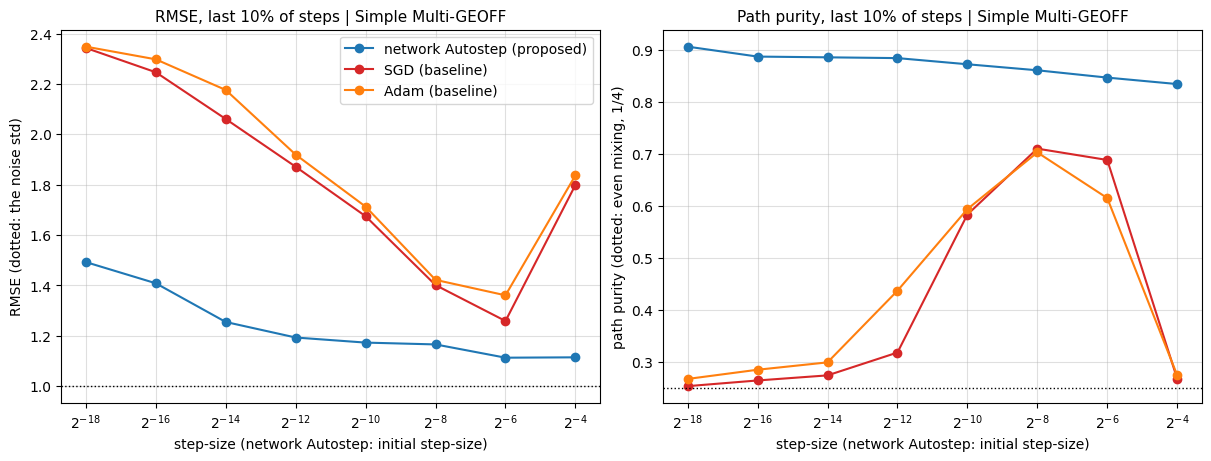

In [ ]:
LABELS = {'network Autostep': 'network Autostep (proposed)', 'SGD': 'SGD (baseline)', 'Adam': 'Adam (baseline)'}
COLORS = {'network Autostep': 'tab:blue', 'SGD': 'tab:red', 'Adam': 'tab:orange'}
final_windows = int(N_STEPS // WINDOW * FINAL_FRACTION)

fig, axes = plt.subplots(1, 2, figsize=(12, 4.5), layout='constrained')
for ax, measure, title in [(axes[0], 'rmse', 'RMSE'), (axes[1], 'purity', 'Path purity')]:
    for learner in LEARNERS:
        values = results[learner][measure][..., -final_windows:].mean(-1)     # (step-size, seed)
        values = np.where(np.isfinite(values), values, np.nan)
        ax.plot(STEP_SIZES, values.mean(1), color=COLORS[learner], marker='o', label=LABELS[learner])
    ax.set_xscale('log', base=2)
    ax.set_xticks(STEP_SIZES)
    ax.set_xlabel('step-size (network Autostep: initial step-size)')
    ax.set_title(f'{title}, last 10% of steps | Simple Multi-GEOFF', fontsize=11)
    ax.grid(alpha=0.4)
axes[0].axhline(NOISE_STD, color='black', ls=':', lw=1)
axes[1].axhline(1 / N_TASKS, color='black', ls=':', lw=1)
axes[0].set_ylabel('RMSE (dotted: the noise std)')
axes[1].set_ylabel(f'path purity (dotted: even mixing, 1/{N_TASKS})')
axes[0].legend()
plt.show()

## Learning curves

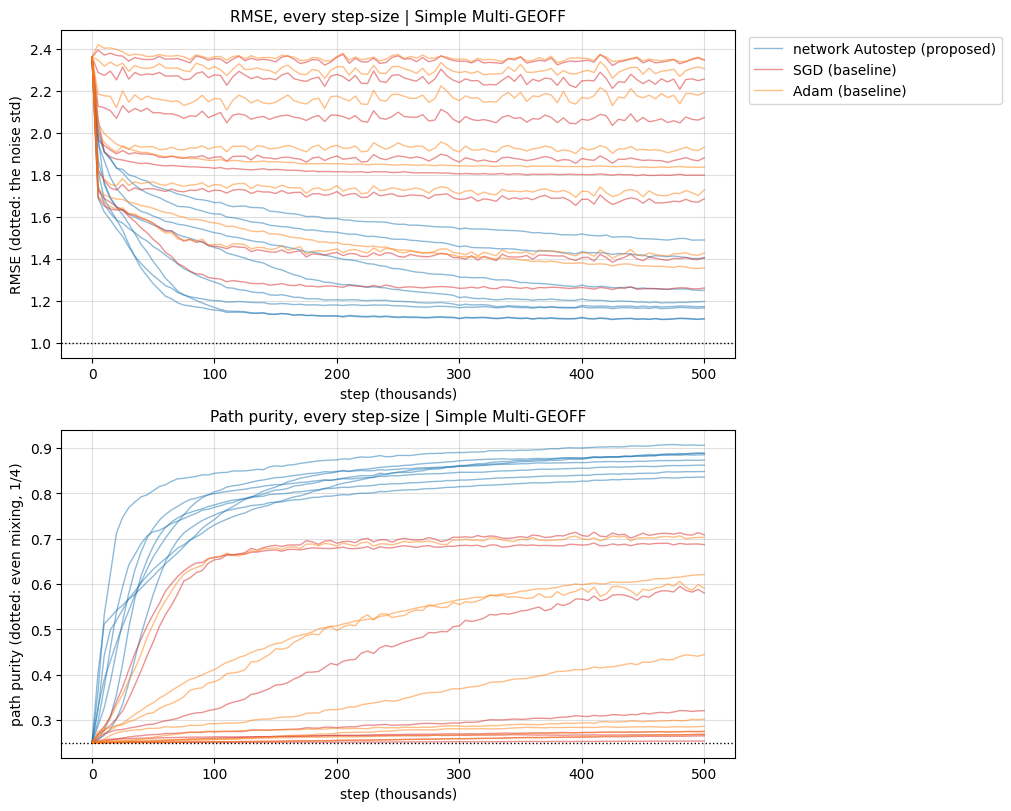

In [ ]:
window_steps = np.concatenate([[1], np.arange(1, N_STEPS // WINDOW + 1) * WINDOW])

fig, axes = plt.subplots(2, 1, figsize=(10, 8), layout='constrained')
for ax, measure, title in [(axes[0], 'rmse', 'RMSE'), (axes[1], 'purity', 'Path purity')]:
    for learner in LEARNERS:
        for i in range(len(STEP_SIZES)):
            values = results[learner][measure][i]       # (seed, 1 + window)
            values = np.where(np.isfinite(values), values, np.nan)
            label = LABELS[learner] if i == 0 else None
            ax.plot(window_steps / 1000, values.mean(0), color=COLORS[learner], alpha=0.5, lw=1, label=label)
    ax.set_xlabel('step (thousands)')
    ax.set_title(f'{title}, every step-size | Simple Multi-GEOFF', fontsize=11)
    ax.grid(alpha=0.4)
axes[0].axhline(NOISE_STD, color='black', ls=':', lw=1)
axes[1].axhline(1 / N_TASKS, color='black', ls=':', lw=1)
axes[0].set_ylabel('RMSE (dotted: the noise std)')
axes[1].set_ylabel(f'path purity (dotted: even mixing, 1/{N_TASKS})')
axes[0].legend(loc='upper left', bbox_to_anchor=(1.01, 1))
plt.show()